# 03 · Liquidation Prediction
Do observable market states predict a new liquidation burst, and do these probabilities help the maker filter?

This notebook distinguishes the historical directional-change experiments (`evt/`, `early_warning/`) from the newer
side-specific Logistic Regression stacking experiment (`maker/`). Their populations, targets and splits differ.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
from research_paths import artifact_dir
import research_report as report
report.style()
def show(fig, name):
    path=ROOT/'artifacts/figures'/name
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)

## Historical DC / Markov / W–L experiment
Directional changes use completed-second midpoint prices and thresholds 2.5/5/10 bps.
A first-order transition matrix produces transition surprise; W averages the last 20 surprises and L is a calibrated
normal-CDF transform. The Markov assumption is an approximation. Open interest is absent and is not replaced by volume.

Historical splits: train through January 29, validation January 30–February 13, historical test February 14–28.
The first 14 days fit nuisance estimators; a 305-second purge protects horizon boundaries.
The final February segment had already appeared in EDA. It is not an independent hidden test.

In [2]:
display(report.table('early_warning','calendar_split.csv').groupby(['split','role']).agg(days=('day','size')))
metrics=report.table('evt','modeling/test_metrics.csv')
display(metrics[['horizon_s','model','n','positives','mse','average_precision','precision','recall']])

days
split      role                              
test       test                            15
train      phi_and_detector_calibration     7
           train                           46
           transition_fit                   7
validation validation                      15

,horizon_s,model,n,positives,mse,average_precision,precision,recall
0,5,logistic,160901,631,0.003919,0.038661,0.076923,0.085578
1,5,constant_train_prevalence,160901,631,0.003906,0.003922,0.000000,0.000000
2,5,lightgbm,160901,631,0.003826,0.043170,0.061756,0.172742
3,20,logistic,160901,2464,0.014797,0.099315,0.159831,0.199269
4,20,constant_train_prevalence,160901,2464,0.015080,0.015314,0.000000,0.000000
5,20,lightgbm,160901,2464,0.014240,0.113653,0.166070,0.263393
6,30,logistic,160901,3492,0.020864,0.109403,0.157802,0.231100
7,30,constant_train_prevalence,160901,3492,0.021234,0.021703,0.000000,0.000000
8,30,lightgbm,160901,3492,0.019985,0.127019,0.182315,0.276919
9,120,logistic,160901,10801,0.061106,0.180807,0.224533,0.266920


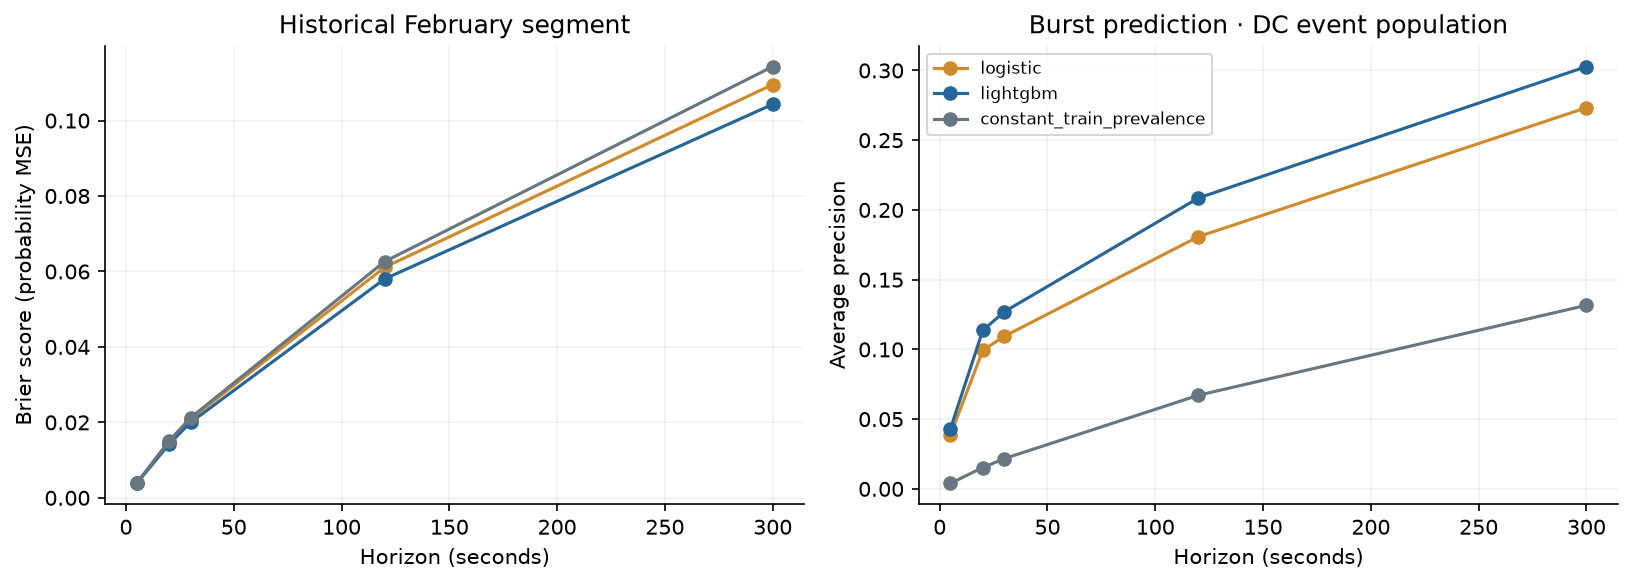

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for model,color in [('logistic','#d18a29'),('lightgbm','#24659a'),('constant_train_prevalence','#687681')]:
    q=metrics[metrics.model.eq(model)].sort_values('horizon_s')
    axes[0].plot(q.horizon_s,q.mse,marker='o',label=model,color=color)
    axes[1].plot(q.horizon_s,q.average_precision,marker='o',label=model,color=color)
axes[0].set(ylabel='Brier score (probability MSE)',xlabel='Horizon (seconds)',title='Historical February segment')
axes[1].set(ylabel='Average precision',xlabel='Horizon (seconds)',title='Burst prediction · DC event population')
axes[1].legend(fontsize=8);fig.tight_layout();show(fig,'burst_prediction.png')

LightGBM improves historical Brier score and average precision relative to logistic across the saved horizons.
Classification thresholds were selected on the earlier validation segment. Precision and recall refer to those frozen
thresholds, not to a common alarm budget. Binary log loss is the classification training objective.

## W–L ablation and reduced 5-second model
The warning model's `full` versus `without_liquidity_score` comparison is distinct from E3/E4.
The later 5-tree, depth-at-most-8, 5-lag revision did not improve the original test MSE;
the negative result remains in the saved comparison.

In [4]:
warning=report.table('early_warning','model_metrics.csv')
display(warning.query("split=='test' and horizon_s==5")[
    ['model','n','brier','average_precision','precision','recall']])
reduced=report.table('evt','reduced_5s/test_evaluation/comparison_by_split.csv')
display(reduced.query("split=='test'")[['model','mse','average_precision','precision','recall','brier_skill_vs_train_prior']])

,model,n,brier,average_precision,precision,recall
1,without_liquidity_score,160700,0.003792,0.055320,0.079778,0.228209
3,full,160700,0.003796,0.053672,0.069936,0.275753
5,constant_train_prevalence,160700,0.003911,0.003927,0.000000,0.000000


,model,mse,average_precision,precision,recall,brier_skill_vs_train_prior
8,lightgbm_reduced_5s,0.003866,0.039960,0.058071,0.266244,0.010397
9,lightgbm_original,0.003826,0.043170,0.061756,0.172742,0.020554
10,logistic_original,0.003919,0.038661,0.076923,0.085578,-0.003176
11,constant_train_prevalence,0.003906,0.003922,0.000000,0.000000,0.000000


## Side-specific probabilities for maker models
A separate StandardScaler + LogisticRegression(C=0.01) pipeline predicts buy/sell burst onset in `(t, t+5s]`.
It trains on a deterministic 20% sample of the 5-second clock. Expanding weekly out-of-fold fits and a 10-second purge
prevent probability features from using their own future labels. Historical DC probabilities are not reused as
calibrated trade-clock probabilities.

In [5]:
lr=report.table('maker','lr_validation_metrics.csv')
display(lr)
display(report.table('maker','lr_brier_comparison.csv').query("symbol=='combined' and block_days==5"))
display(report.table('maker','lr_upper_probability_bins.csv').query("symbol=='combined'"))

,symbol,side,n,positives,prevalence,brier,constant_brier,log_loss,pr_auc_average_precision,ece
0,btcusdt,buy,483838,557,0.001151,0.001133,0.001150,0.006571,0.030296,0.000237
1,btcusdt,sell,483838,659,0.001362,0.001339,0.001360,0.007465,0.034534,0.000215
2,ethusdt,buy,483838,478,0.000988,0.001014,0.000987,0.005972,0.024031,0.000233
3,ethusdt,sell,483838,644,0.001331,0.001310,0.001330,0.007525,0.031712,0.000226
4,combined,buy,967676,1035,0.001070,0.001073,0.001069,0.006272,0.026147,0.000083
5,combined,sell,967676,1303,0.001347,0.001325,0.001345,0.007495,0.032878,0.000222


,symbol,side,block_days,brier_improvement_over_constant,ci_low,ci_high,confidence_level,multiplicity
9,combined,buy,5,-0.000005,-0.000027,0.000010,0.991667,Bonferroni6 symbol/side comparisons; retrospec...
11,combined,sell,5,0.000020,0.000011,0.000035,0.991667,Bonferroni6 symbol/side comparisons; retrospec...


,symbol,side,bin,rows,positives,predicted,observed,min_probability,max_probability
12,combined,buy,90-99 percentile,87091,555,0.004938,0.006373,0.001197,0.021089
13,combined,buy,99-99.9 percentile,8709,278,0.036605,0.031921,0.021089,0.081181
14,combined,buy,99.9-100 percentile,968,47,0.144515,0.048554,0.081181,0.998607
15,combined,sell,90-99 percentile,87091,685,0.008431,0.007865,0.002088,0.030648
16,combined,sell,99-99.9 percentile,8709,355,0.045361,0.040762,0.030648,0.080056
17,combined,sell,99.9-100 percentile,968,58,0.117501,0.059917,0.080056,0.846194


For combined buy targets, Brier is about 0.001073 versus 0.001069 for the train-prior constant; there is no improvement.
For sell targets it is about 0.001325 versus 0.001345. The saved block-bootstrap comparison supports the sell-side
Brier improvement, but this does not establish an economic maker benefit. E5/E7 answer that separate question.

## Conclusion
Burst prediction is implemented and has useful ranking signal in these historical populations.
Probability quality, event recall and maker Score are different evaluations. The reduced-model and W–L ablations
do not establish a universal gain. No unseen test period has been evaluated.